<a href="https://colab.research.google.com/github/prateek-suryavanshi465/student-performance--prediction-ml/blob/main/student_prediction_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [13]:
print("my first data science project")
print("student performance prediction")
print("i am learning machine learning")

my first data science project
student performance prediction
i am learning machine learning


In [14]:
import pandas as pd

data = {
    "Study_Hours": [2, 4, 3, 5, 6, 1, 7, 4, 8, 2],
    "Attendance": [60, 80, 70, 90, 95, 50, 98, 75, 99, 65],
    "Previous_Marks": [50, 65, 60, 75, 80, 40, 90, 70, 95, 55],
    "Final_Marks": [52, 68, 62, 78, 85, 42, 92, 72, 96, 57]
}

df = pd.DataFrame(data)

print(df)

   Study_Hours  Attendance  Previous_Marks  Final_Marks
0            2          60              50           52
1            4          80              65           68
2            3          70              60           62
3            5          90              75           78
4            6          95              80           85
5            1          50              40           42
6            7          98              90           92
7            4          75              70           72
8            8          99              95           96
9            2          65              55           57


In [15]:
print("Dataset Shape:")
print(df.shape)

print("\nDataset Information:")
print(df.info())

print("\nStatistical Summary:")
print(df.describe())

Dataset Shape:
(10, 4)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   Study_Hours     10 non-null     int64
 1   Attendance      10 non-null     int64
 2   Previous_Marks  10 non-null     int64
 3   Final_Marks     10 non-null     int64
dtypes: int64(4)
memory usage: 452.0 bytes
None

Statistical Summary:
       Study_Hours  Attendance  Previous_Marks  Final_Marks
count    10.000000   10.000000       10.000000    10.000000
mean      4.200000   78.200000       68.000000    70.400000
std       2.299758   17.086707       17.511901    17.626999
min       1.000000   50.000000       40.000000    42.000000
25%       2.250000   66.250000       56.250000    58.250000
50%       4.000000   77.500000       67.500000    70.000000
75%       5.750000   93.750000       78.750000    83.250000
max       8.000000   99.000000       95.000000

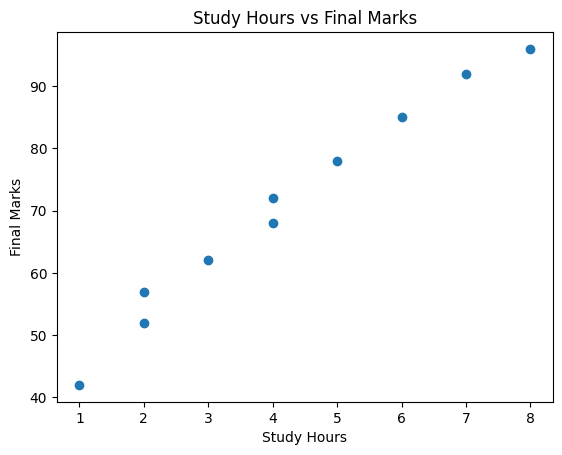

In [16]:
import matplotlib.pyplot as plt

plt.scatter(df["Study_Hours"], df["Final_Marks"])

plt.xlabel("Study Hours")
plt.ylabel("Final Marks")
plt.title("Study Hours vs Final Marks")

plt.show()

In [17]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

# Input features
X = df[["Study_Hours", "Attendance", "Previous_Marks"]]

# Output we want to predict
y = df["Final_Marks"]

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create and train the model
model = LinearRegression()
model.fit(X_train, y_train)

print("Machine Learning model trained successfully!")

Machine Learning model trained successfully!


In [18]:
new_student = [[5, 85, 75]]

# Predict final marks
predicted_marks = model.predict(new_student)

print("Study Hours:", 5)
print("Attendance:", 85, "%")
print("Previous Marks:", 75)
print("Predicted Final Marks:", round(predicted_marks[0], 2))

Study Hours: 5
Attendance: 85 %
Previous Marks: 75
Predicted Final Marks: 77.65


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [19]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Predict marks for the test data
y_pred = model.predict(X_test)

# Evaluate the model
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Actual Marks:", list(y_test))
print("Predicted Marks:", y_pred.round(2))
print("Mean Absolute Error:", round(mae, 2))
print("Mean Squared Error:", round(mse, 2))
print("R2 Score:", round(r2, 2))

Actual Marks: [96, 68]
Predicted Marks: [97.21 68.55]
Mean Absolute Error: 0.88
Mean Squared Error: 0.88
R2 Score: 1.0


In [20]:
import pandas as pd

results = pd.DataFrame({
    "Actual_Marks": y_test.values,
    "Predicted_Marks": y_pred.round(2)
})

print(results)

   Actual_Marks  Predicted_Marks
0            96            97.21
1            68            68.55


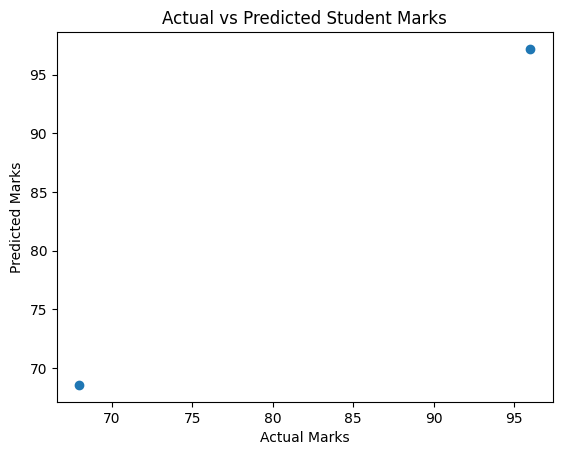

In [21]:
import matplotlib.pyplot as plt

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Marks")
plt.ylabel("Predicted Marks")
plt.title("Actual vs Predicted Student Marks")

plt.show()

In [22]:
import pandas as pd

# Display project information
print("STUDENT PERFORMANCE PREDICTION")
print("--------------------------------")

print("Features used:")
print("1. Study Hours")
print("2. Attendance")
print("3. Previous Marks")

print("\nMachine Learning Model: Linear Regression")
print("Model is ready for predictions!")

STUDENT PERFORMANCE PREDICTION
--------------------------------
Features used:
1. Study Hours
2. Attendance
3. Previous Marks

Machine Learning Model: Linear Regression
Model is ready for predictions!


In [23]:
!pip install streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 94.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 104.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [streamlit]


In [24]:
%%writefile app.py

import streamlit as st
import pandas as pd

st.title("Student Performance Prediction")

st.write("Enter student details to predict final marks.")

study_hours = st.number_input(
    "Study Hours Per Day",
    min_value=0.0,
    max_value=24.0,
    value=4.0
)

attendance = st.number_input(
    "Attendance (%)",
    min_value=0.0,
    max_value=100.0,
    value=85.0
)

previous_marks = st.number_input(
    "Previous Exam Marks",
    min_value=0.0,
    max_value=100.0,
    value=70.0
)

if st.button("Predict Marks"):
    if "model" in globals():
        student = pd.DataFrame({
            "Study_Hours": [study_hours],
            "Attendance": [attendance],
            "Previous_Marks": [previous_marks]
        })

        prediction = model.predict(student)[0]

        prediction = max(0, min(100, prediction))

        st.success(
            f"Predicted Final Marks: {prediction:.2f}"
        )
    else:
        st.error(
            "Model not found. Please load the trained model first."
        )

Writing app.py


In [25]:
import joblib

joblib.dump(model, "student_model.pkl")

print("Machine Learning model saved successfully!")

Machine Learning model saved successfully!


In [26]:
%%writefile app.py

import streamlit as st
import pandas as pd
import joblib

model = joblib.load("student_model.pkl")

st.title("Student Performance Prediction")
st.write("Predict student marks using Machine Learning.")

study_hours = st.number_input(
    "Study Hours Per Day", 0.0, 24.0, 4.0
)

attendance = st.number_input(
    "Attendance (%)", 0.0, 100.0, 85.0
)

previous_marks = st.number_input(
    "Previous Marks", 0.0, 100.0, 70.0
)

if st.button("Predict Marks"):
    student = pd.DataFrame({
        "Study_Hours": [study_hours],
        "Attendance": [attendance],
        "Previous_Marks": [previous_marks]
    })

    prediction = model.predict(student)[0]
    prediction = max(0, min(100, prediction))

    st.success(f"Predicted Final Marks: {prediction:.2f}")

Overwriting app.py


In [27]:
import shutil

shutil.make_archive(
    "student_performance_project",
    "zip",
    ".",
    logger=None
)

print("Project ZIP created!")


Project ZIP created!


In [28]:
!pip install -q pyngrok


In [29]:
import os

print("app.py exists:", os.path.exists("app.py"))
print("Model exists:", os.path.exists("student_model.pkl"))
print("Project ZIP exists:", os.path.exists("student_performance_project.zip"))


app.py exists: True
Model exists: True
Project ZIP exists: True


In [30]:
import os

print("app.py exists:", os.path.exists("app.py"))
print("Model exists:", os.path.exists("student_model.pkl"))
print("Project ZIP exists:", os.path.exists("student_performance_project.zip"))

app.py exists: True
Model exists: True
Project ZIP exists: True


In [31]:
import os

print("app.py exists:", os.path.exists("app.py"))
print("Model exists:", os.path.exists("student_model.pkl"))
print("Project ZIP exists:", os.path.exists("student_performance_project.zip"))

app.py exists: True
Model exists: True
Project ZIP exists: True


In [32]:
!streamlit run app.py &>/content/streamlit.log &


In [33]:
!cat /content/streamlit.log

In [34]:
from google.colab import output
output.serve_kernel_port_as_window(8503)


Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

In [35]:
!streamlit run /content/app.py --server.port 8501 --server.address 0.0.0.0 --server.enableCORS false --server.enableXsrfProtection false --server.headless true > /content/streamlit.log 2>&1 &



In [36]:
import os

print("App:", os.path.exists("/content/app.py"))
print("Model:", os.path.exists("/content/student_model.pkl"))
print("Ready to check Streamlit")

App: True
Model: True
Ready to check Streamlit


In [37]:
import subprocess
import time

with open("/content/streamlit.log", "w") as log:
    process = subprocess.Popen(
        [
            "python", "-m", "streamlit", "run", "/content/app.py",
            "--server.port=8501",
            "--server.address=0.0.0.0",
            "--server.enableCORS=false",
            "--server.enableXsrfProtection=false",
            "--server.headless=true"
        ],
        stdout=log,
        stderr=subprocess.STDOUT,
        start_new_session=True
    )

time.sleep(5)

print("Streamlit process ID:", process.pid)

with open("/content/streamlit.log", "r") as f:
    print(f.read()[-3000:])

Streamlit process ID: 3998





In [38]:
import subprocess
import time

with open("/content/streamlit_8502.log", "w") as log:
    process = subprocess.Popen(
        [
            "python", "-m", "streamlit", "run", "/content/app.py",
            "--server.port=8502",
            "--server.address=0.0.0.0",
            "--server.enableCORS=false",
            "--server.enableXsrfProtection=false",
            "--server.headless=true"
        ],
        stdout=log,
        stderr=subprocess.STDOUT,
        start_new_session=True
    )

time.sleep(5)

with open("/content/streamlit_8502.log", "r") as f:
    print(f.read()[-3000:])

In [39]:
!ps -ef | grep -E '[s]treamlit|[s]t.server'

root        3994       1 35 05:37 ?        00:00:03 /usr/bin/python3 /usr/local/bin/streamlit run app.py
root        3997       1 35 05:37 ?        00:00:03 /usr/bin/python3 /usr/local/bin/streamlit run /content/app.py --server.port 8501 --server.address 0.0.0.0 --server.enableCORS false --server.enableXsrfProtection false --server.headless true
root        3998    2820 36 05:37 ?        00:00:03 python3 -m streamlit run /content/app.py --server.port=8501 --server.address=0.0.0.0 --server.enableCORS=false --server.enableXsrfProtection=false --server.headless=true
root        4049    2820 33 05:37 ?        00:00:01 python3 -m streamlit run /content/app.py --server.port=8502 --server.address=0.0.0.0 --server.enableCORS=false --server.enableXsrfProtection=false --server.headless=true


In [40]:
import subprocess
import time

subprocess.run(["pkill", "-f", "streamlit run app.py"])

time.sleep(3)

print("Stopped old Streamlit processes.")

Stopped old Streamlit processes.


In [41]:
!ps -ef | grep '[s]treamlit run app.py'

In [42]:
import subprocess
import time

with open("/content/streamlit.log", "w") as log:
    process = subprocess.Popen(
        [
            "python", "-m", "streamlit", "run", "/content/app.py",
            "--server.port=8501",
            "--server.address=0.0.0.0",
            "--server.headless=true"
        ],
        stdout=log,
        stderr=subprocess.STDOUT,
        start_new_session=True
    )

time.sleep(5)

with open("/content/streamlit.log", "r") as f:
    print(f.read())

In [47]:
from google.colab import output

output.serve_kernel_port_as_iframe(8501)

<IPython.core.display.Javascript object>

In [48]:
# Check missing values
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
Study_Hours       0
Attendance        0
Previous_Marks    0
Final_Marks       0
dtype: int64


In [49]:
# Check duplicate records
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 0


In [50]:
# Dataset overview

print("Dataset Shape:", df.shape)

print("\nFirst 5 Records:")
display(df.head())

print("\nStatistical Summary:")
display(df.describe())

print("\nColumn Data Types:")
print(df.dtypes)

Dataset Shape: (10, 4)

First 5 Records:


,Study_Hours,Attendance,Previous_Marks,Final_Marks
0,2,60,50,52
1,4,80,65,68
2,3,70,60,62
3,5,90,75,78
4,6,95,80,85



Statistical Summary:


,Study_Hours,Attendance,Previous_Marks,Final_Marks
count,10.000000,10.000000,10.000000,10.000000
mean,4.200000,78.200000,68.000000,70.400000
std,2.299758,17.086707,17.511901,17.626999
min,1.000000,50.000000,40.000000,42.000000
25%,2.250000,66.250000,56.250000,58.250000
50%,4.000000,77.500000,67.500000,70.000000
75%,5.750000,93.750000,78.750000,83.250000
max,8.000000,99.000000,95.000000,96.000000



Column Data Types:
Study_Hours       int64
Attendance        int64
Previous_Marks    int64
Final_Marks       int64
dtype: object


In [51]:
# Model Training and Evaluation

import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score

# Select input and target columns
X = df[['Study_Hours', 'Attendance', 'Previous_Marks']]
y = df['Final_Marks']

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict test data
y_pred = model.predict(X_test)

# Evaluate model
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MODEL EVALUATION RESULTS")
print("------------------------")
print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 2))

MODEL EVALUATION RESULTS
------------------------
MAE: 0.88
MSE: 0.88
RMSE: 0.94
R2 Score: 1.0


In [53]:
import joblib

# Save trained model
joblib.dump(model, 'student_performance_model.pkl')

print("Model saved successfully!")

Model saved successfully!


In [54]:
print("Total dataset records:", len(df))
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Input features:", list(X.columns))

Total dataset records: 10
Training records: 8
Testing records: 2
Input features: ['Study_Hours', 'Attendance', 'Previous_Marks']


In [55]:
# Save dataset
df.to_csv("student_performance_dataset.csv", index=False)

print("Dataset saved successfully!")

Dataset saved successfully!


In [56]:
from google.colab import files

files.download("student_performance_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>